# 03 · Segmentación de la participación electoral
Se ajusta K-means ponderado con seis perfiles a partir de participación media, brecha electoral,
cambio reciente e irregularidad. La edad, el sexo y el territorio se utilizan después para caracterizar
los grupos, de acuerdo con el Reto 1 del hackatón del INE.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, joblib
from sklearn import config_context
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (silhouette_score, silhouette_samples, calinski_harabasz_score,
                             davies_bouldin_score, adjusted_rand_score)
from threadpoolctl import threadpool_limits
import utils as U
sns.set_theme(style="whitegrid")
# Rosa mexicano, maíz, azul Talavera, morado, verde y naranja.
PALETA_BASE = ["#E6007E", "#E5AD00", "#0066CC", "#812AA6", "#008F5A", "#F06400"]
PALETA = dict(enumerate(PALETA_BASE))
sns.set_palette(PALETA_BASE)
plt.rcParams["figure.dpi"] = 110
pd.options.display.float_format = "{:,.3f}".format
if (U.DIR_PROC / "FUENTE.txt").read_text(encoding="utf-8").strip() != "REAL":
    raise ValueError("Se requieren los datos reales preparados en 01 y 02.")
unidades = pd.read_csv(U.DIR_PROC / "unidades.csv")
ANIOS = U.ANIOS
COLS_TASA = [f"tasa_{a}" for a in ANIOS]
print("Matriz:", unidades.shape)


Matriz: (12000, 95)


## 1. Variables y ponderación
Las cuatro variables se estandarizan. El peso de cada segmento es proporcional a la raíz
cuadrada de su denominador medio.

In [2]:
FEATURES_SET = "participacion"
FEATURES = U.VARIABLES_PARTICIPACION
K_FINAL = 6
CANDIDATO_FINAL = "km_participacion"
N_INIT_KMEANS = 50
N_BOOT = 20
FRAC_SUBMUESTRA = 0.8
SIL_MUESTRA = 2_000
UMBRAL_ARI = 0.8
VERSION_MODELO = U.VERSION_MODELO

faltan = set(FEATURES + U.CURVATURAS + U.CURVATURAS_REL + ["ln_media", "denominador_medio", "version_preprocesado",
                       "n_elecciones_validas", "n_tasas_imputadas", "version_variables", "nivel_territorial", "id_distrito"]) - set(unidades)
if faltan:
    raise ValueError(f"Ejecuta el 02 actualizado. Faltan: {sorted(faltan)}")
if not unidades.version_preprocesado.eq("ccpc_edad114_especificados").all() or not unidades.nivel_territorial.eq("distrito").all():
    raise ValueError("Se requiere la matriz distrital correspondiente al notebook 02.")
if len(unidades) <= K_FINAL:
    raise ValueError("Se requieren más segmentos que perfiles para ajustar el modelo.")
if not unidades.n_elecciones_validas.eq(6).all() or not unidades.n_tasas_imputadas.eq(0).all():
    raise ValueError("Se requieren seis elecciones observadas y ninguna imputación.")

if not unidades.version_variables.eq(U.VERSION_VARIABLES).all():
    raise ValueError("Ejecuta 02 actualizado: se requieren las cuatro entradas de participación.")
ln = unidades.ln_media.to_numpy(float)
soporte = unidades.denominador_medio.to_numpy(float)
fuera = np.zeros(len(unidades), dtype=bool)
idx_ajuste = np.arange(len(unidades))
w = np.sqrt(soporte)
w /= w[idx_ajuste].mean()
X_raw = unidades[FEATURES].to_numpy(float)
def ajustar(idx=None, seed=U.SEED):
    idx = idx_ajuste if idx is None else idx
    esc = StandardScaler().fit(X_raw[idx])
    datos = esc.transform(X_raw[idx])
    modelo = KMeans(n_clusters=K_FINAL, n_init=N_INIT_KMEANS, random_state=seed)
    with threadpool_limits(limits=2):
        modelo.fit(datos, sample_weight=w[idx])
    return modelo, esc

def evaluar(modelo, esc):
    datos = esc.transform(X_raw[idx_ajuste])
    etiquetas = modelo.predict(datos)
    cuenta = np.unique(etiquetas, return_counts=True)[1]
    resultado = dict(n_grupos_observados=len(cuenta), tam_min_pct=100*cuenta.min()/len(etiquetas),
        inercia=modelo.inertia_, convergio=True, silueta=np.nan, silueta_referencia=np.nan,
        calinski_harabasz=np.nan, davies_bouldin=np.nan)
    if 1 < len(cuenta) < len(etiquetas):
        with config_context(working_memory=128):
            resultado["silueta"] = silhouette_score(datos, etiquetas,
                sample_size=min(SIL_MUESTRA,len(datos)), random_state=U.SEED)
            resultado["silueta_referencia"] = resultado["silueta"]  # Alias para las tablas existentes; mismo espacio.
        resultado["calinski_harabasz"] = calinski_harabasz_score(datos, etiquetas)
        resultado["davies_bouldin"] = davies_bouldin_score(datos, etiquetas)
    return resultado
print("K-Means de participación: seis perfiles | segmentos:", len(idx_ajuste))


K-Means de participación: seis perfiles | segmentos: 12000


## 2. Ajuste del modelo
Se fijan seis perfiles como decisión de diseño y se realizan 50 inicializaciones.

In [3]:
print(f"[03] Ajustando K-Means con {K_FINAL} perfiles...", flush=True)
modelo_final, escalador = ajustar()
spec_final = {"algoritmo": "kmeans", "escala": "standard", "ponderado": True, "features_set": FEATURES_SET}
evaluacion = pd.DataFrame([dict(candidato=CANDIDATO_FINAL, k=K_FINAL, **spec_final,
                              **evaluar(modelo_final, escalador))])


[03] Ajustando K-Means con 6 perfiles...


## 3. Separación de los perfiles
La silueta inicial se calcula con una muestra reproducible de hasta 2,000 segmentos.
La evaluación final utiliza todos los segmentos.

In [4]:
display(evaluacion[["candidato", "k", "silueta", "davies_bouldin", "tam_min_pct"]].rename(
    columns={"silueta": "silueta_preliminar_muestra"}))


,candidato,k,silueta_preliminar_muestra,davies_bouldin,tam_min_pct
0,km_participacion,6,0.233,1.232,10.183


## 4. Estabilidad territorial
Se reajustan el escalador y el modelo en 20 submuestras de 25 entidades. El ARI compara las
particiones predichas del conjunto completo; Jaccard resume la coincidencia de cada perfil
con el ajuste de referencia. Esta prueba evalúa estabilidad interna con los indicadores del 02 fijos.

In [5]:
print(f"[03][{FEATURES_SET}] Iniciando estabilidad por entidad y Jaccard.", flush=True)
def evaluar_estabilidad():
    k = K_FINAL
    candidato = CANDIDATO_FINAL
    ref = modelo_final.predict(escalador.transform(X_raw[idx_ajuste]))
    grupos = np.unique(ref)
    jaccards = {int(c): [] for c in grupos}
    preds = []
    rng = np.random.default_rng(U.SEED + 100*k)
    for repeticion in range(N_BOOT):
        if repeticion == 0 or (repeticion + 1) % 5 == 0:
            print(f"[03][{FEATURES_SET}] Estabilidad {candidato}, k={k}: iniciando repetición {repeticion+1}/{N_BOOT} "
                  f"({len(preds)} válidas previas)", flush=True)
        entidades = unidades.iloc[idx_ajuste].entidad.unique()
        seleccionadas = rng.choice(entidades, size=max(1,int(FRAC_SUBMUESTRA*len(entidades))), replace=False)
        idx = idx_ajuste[unidades.iloc[idx_ajuste].entidad.isin(seleccionadas).to_numpy()]
        seed = int(rng.integers(1_000_000_000))
        try:
            modelo, esc = ajustar(idx=idx, seed=seed)
            pred = modelo.predict(esc.transform(X_raw[idx_ajuste]))
        except (ValueError, np.linalg.LinAlgError):
            continue
        preds.append(pred)
        for c in grupos:
            mascara = ref == c
            semejanzas = [np.sum(mascara & (pred == otro)) / np.sum(mascara | (pred == otro))
                          for otro in np.unique(pred)]
            jaccards[int(c)].append(max(semejanzas))
    print(f"[03][{FEATURES_SET}] Estabilidad {candidato}, k={k}: {N_BOOT}/{N_BOOT} intentos, "
          f"{len(preds)} válidos.", flush=True)
    aris = [adjusted_rand_score(preds[i], preds[j]) for i in range(len(preds)) for j in range(i+1, len(preds))]
    detalle = pd.DataFrame([
        dict(cluster_original=c, jaccard_media=np.mean(valores) if valores else np.nan,
             jaccard_p10=np.quantile(valores,.1) if valores else np.nan,
             repeticiones_validas=len(preds))
        for c, valores in jaccards.items()])
    return (dict(ari_estabilidad=np.mean(aris) if aris else np.nan,
                 ari_desv=np.std(aris) if aris else np.nan,
                 jaccard_minimo=detalle.jaccard_media.min(), repeticiones_validas=len(preds)), detalle)

medidas_estabilidad, detalle_entidad = evaluar_estabilidad()
for campo, valor in medidas_estabilidad.items():
    evaluacion.loc[0, campo + "_entidad"] = valor
display(evaluacion[["candidato", "k", "silueta", "ari_estabilidad_entidad", "jaccard_minimo_entidad"]])


[03][participacion] Iniciando estabilidad por entidad y Jaccard.
[03][participacion] Estabilidad km_participacion, k=6: iniciando repetición 1/20 (0 válidas previas)
[03][participacion] Estabilidad km_participacion, k=6: iniciando repetición 5/20 (4 válidas previas)
[03][participacion] Estabilidad km_participacion, k=6: iniciando repetición 10/20 (9 válidas previas)
[03][participacion] Estabilidad km_participacion, k=6: iniciando repetición 15/20 (14 válidas previas)
[03][participacion] Estabilidad km_participacion, k=6: iniciando repetición 20/20 (19 válidas previas)
[03][participacion] Estabilidad km_participacion, k=6: 20/20 intentos, 20 válidos.


,candidato,k,silueta,ari_estabilidad_entidad,jaccard_minimo_entidad
0,km_participacion,6,0.233,0.698,0.690


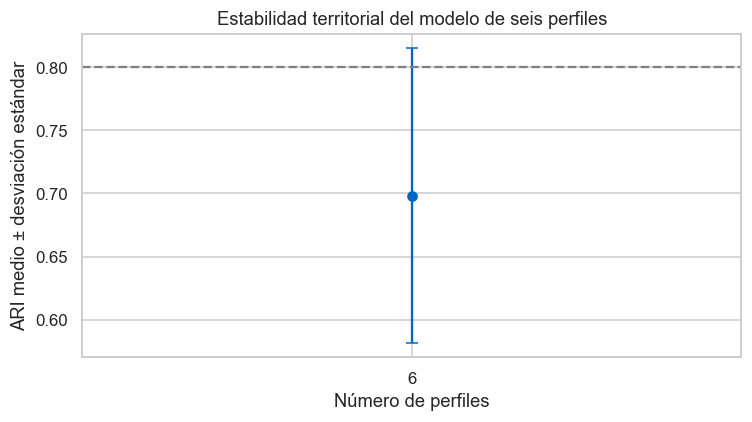

In [6]:
fig, ax = plt.subplots(figsize=(7, 4))
fila = evaluacion.iloc[0]
ax.errorbar([K_FINAL], [fila.ari_estabilidad_entidad], yerr=[fila.ari_desv_entidad],
            marker="o", capsize=4, color=PALETA[2])
ax.axhline(UMBRAL_ARI, color="gray", ls="--")
ax.set(title="Estabilidad territorial del modelo de seis perfiles", xlabel="Número de perfiles",
       ylabel="ARI medio ± desviación estándar", xticks=[K_FINAL])
plt.tight_layout(); plt.savefig(U.ruta_set(U.DIR_FIG, "estabilidad_bootstrap.png", FEATURES_SET), dpi=180, bbox_inches="tight"); plt.show(); plt.close()


## 5. Resumen del modelo
Se registra el ajuste y sus métricas. El valor 0.80 de ARI se utiliza como referencia de estabilidad.

In [7]:
seleccion = evaluacion.iloc[0]
CANDIDATO_FINAL, K_FINAL = str(seleccion.candidato), int(seleccion.k)
ALGORITMO_FINAL, ESCALADOR = str(seleccion.algoritmo), str(seleccion.escala)
FEATURES_SET = str(seleccion.features_set)
FEATURES = U.VARIABLES_PARTICIPACION
X_raw = unidades[FEATURES].to_numpy(float)
CRITERIO_SELECCION = "Seis perfiles de participación; nivel, brecha, cambio reciente e irregularidad observados"
if seleccion.ari_estabilidad_entidad < UMBRAL_ARI:
    CRITERIO_SELECCION += "; estabilidad inferior a 0.80"
print("Modelo:", CANDIDATO_FINAL, "| perfiles:", K_FINAL)
print("Silueta preliminar (muestra):", round(seleccion.silueta, 3))

display(seleccion.to_frame("valor"))
metricas = evaluacion.set_index("k").copy()


Modelo: km_participacion | perfiles: 6
Silueta preliminar (muestra): 0.233
Edad, sexo y territorio se reservan para la interpretación posterior.


,valor
candidato,km_participacion
k,6
algoritmo,kmeans
escala,standard
ponderado,True
features_set,participacion
n_grupos_observados,6
tam_min_pct,10.183
inercia,"19,006.414"
convergio,True


## 6. Asignación y proyección de los perfiles
Los identificadores se ordenan por participación media. Se calcula la silueta individual y se
proyectan las cuatro variables mediante PCA para facilitar la lectura del agrupamiento.

In [8]:
print("[03] Preparando el modelo seleccionado y los diagnósticos individuales...", flush=True)
X = escalador.transform(X_raw)
crudas = modelo_final.predict(X)
w_final = w.copy() if spec_final["ponderado"] else np.ones(len(unidades))
medias = {c: np.average(unidades.loc[crudas == c, FEATURES[0]], weights=w_final[crudas == c])
          for c in np.unique(crudas)}
orden = sorted(medias, key=medias.get)
mapa = {viejo:nuevo for nuevo,viejo in enumerate(orden)}
unidades["cluster"] = np.array([mapa[c] for c in crudas])
unidades["peso_clustering"] = w_final
unidades["variables_clustering"] = ";".join(FEATURES)
unidades["algoritmo_clustering"] = ALGORITMO_FINAL
unidades["candidato_modelo"] = CANDIDATO_FINAL
unidades["escalador_clustering"] = ESCALADOR
unidades["version_modelo"] = VERSION_MODELO
unidades["features_set"] = FEATURES_SET
unidades["fuera_de_ajuste"] = fuera
unidades["criterio_seleccion"] = CRITERIO_SELECCION
unidades["silueta_individual"] = np.nan
unidades["silueta_individual_referencia"] = np.nan
with config_context(working_memory=128):
    unidades.loc[~fuera,"silueta_individual"] = silhouette_samples(X[idx_ajuste], crudas[idx_ajuste])
    unidades.loc[~fuera,"silueta_individual_referencia"] = unidades.loc[~fuera,"silueta_individual"].to_numpy()

cent = U.media_ponderada(unidades, FEATURES, "peso_clustering", "cluster").sort_index()
cent["n_segmentos"] = unidades.cluster.value_counts().sort_index()
cent["%_segmentos"] = 100 * cent.n_segmentos / len(unidades)
centros_originales = modelo_final.cluster_centers_
centros_modelo = pd.DataFrame(escalador.inverse_transform(centros_originales)[orden],
                             columns=FEATURES, index=pd.Index(range(K_FINAL),name="cluster"))
# Los diagnósticos por perfil se construyen una sola vez en la sección siguiente.

# Actualizar las métricas globales con la evaluación exacta ya disponible.
silueta_exacta = float(unidades.silueta_individual.mean())
evaluacion.loc[:, ["silueta", "silueta_referencia"]] = silueta_exacta
seleccion = evaluacion.iloc[0].copy()
metricas = evaluacion.set_index("k").copy()
print(f"Silueta exacta: {silueta_exacta:.3f}")


[03] Preparando el modelo seleccionado y los diagnósticos individuales...
Silueta exacta: 0.238


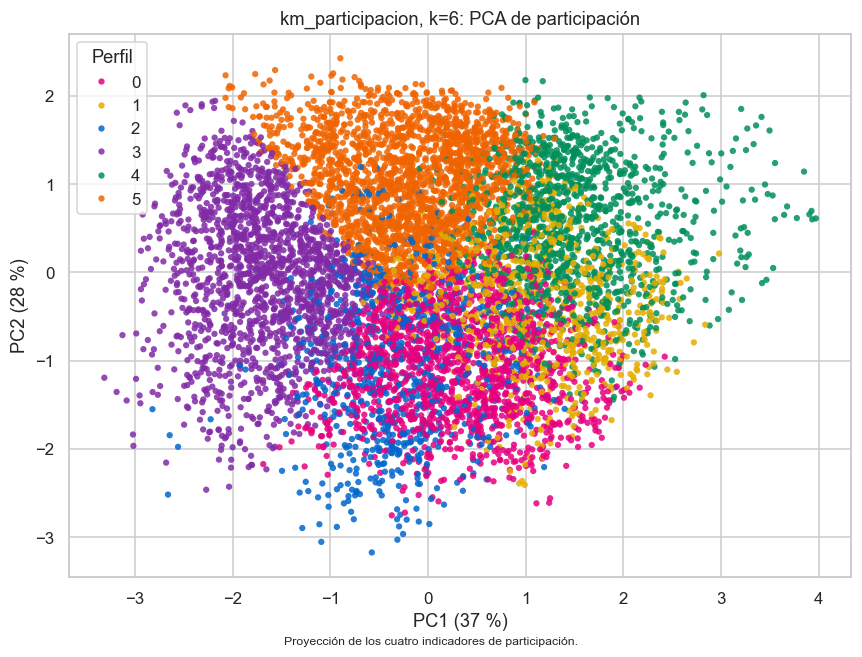

In [9]:
rng = np.random.default_rng(U.SEED)
pca2 = PCA(n_components=2).fit(X[idx_ajuste])
Z = pca2.transform(X)
m = rng.choice(idx_ajuste, size=min(8000,len(idx_ajuste)), replace=False)
plt.figure(figsize=(8,6))
sns.scatterplot(x=Z[m,0],y=Z[m,1],hue=unidades.cluster.to_numpy()[m],
                palette=PALETA,hue_order=list(PALETA),legend="full",s=17,alpha=.85,linewidth=0)
plt.xlabel(f"PC1 ({pca2.explained_variance_ratio_[0]*100:.0f} %)")
plt.ylabel(f"PC2 ({pca2.explained_variance_ratio_[1]*100:.0f} %)")
plt.title(f"{CANDIDATO_FINAL}, k={K_FINAL}: PCA de participación")
plt.legend(title="Perfil")
plt.figtext(.5, .01, "Proyección de los cuatro indicadores de participación.", ha="center", fontsize=8)
plt.tight_layout(); plt.savefig(U.ruta_set(U.DIR_FIG, "proyeccion_pca.png", FEATURES_SET), dpi=180, bbox_inches="tight"); plt.show(); plt.close()


## 7. Diagnósticos y exportación
Se resumen la composición demográfica y territorial, la variación dentro de los perfiles y su
estabilidad. Las asignaciones, el modelo y las tablas se guardan para la caracterización del 04.

In [10]:
print("[03] Calculando diagnósticos del K-Means seleccionado...", flush=True)
ajuste_final = unidades.iloc[idx_ajuste].copy()
variables_diagnostico = list(dict.fromkeys(
    U.VARIABLES_PARTICIPACION + U.VARIABLES_ACTUALES + U.CURVATURAS + U.VARIABLES_RELATIVAS + U.CURVATURAS_REL
))
asociaciones_factores = U.asociaciones_factores(ajuste_final, ajuste_final.cluster.to_numpy())
heterogeneidad, sd_intra = U.heterogeneidad_perfiles(
    ajuste_final, ajuste_final.cluster.to_numpy(), variables_diagnostico
)
diagnostico_perfiles = ajuste_final.groupby("cluster").agg(
    n_segmentos=("cluster", "size"),
    silueta_media=("silueta_individual", "mean"),
    silueta_mediana=("silueta_individual", "median"),
    silueta_p10=("silueta_individual", lambda s: s.quantile(.1)),
    porcentaje_silueta_negativa=("silueta_individual", lambda s: 100*s.lt(0).mean()),
    silueta_media_referencia=("silueta_individual_referencia", "mean"),
)
detalle_entidad = detalle_entidad.copy()
detalle_entidad["cluster"] = detalle_entidad.cluster_original.map(mapa)
diagnostico_perfiles = diagnostico_perfiles.join(
    detalle_entidad.set_index("cluster")[["jaccard_media", "jaccard_p10", "repeticiones_validas"]]
    .add_suffix("_entidad")
)
for variable in U.VARIABLES_ACTUALES + U.CURVATURAS:
    datos = sd_intra.loc[sd_intra.variable.eq(variable)].set_index("cluster")
    diagnostico_perfiles["sd_intra_" + variable] = datos.sd_intra
    diagnostico_perfiles["eta2_entre_perfiles_" + variable] = datos.eta2_entre_perfiles

representacion_edades = unidades.assign(
    en_ajuste=~fuera, ln_ajuste=unidades.ln_media.where(~fuera, 0)
).groupby("grupo_edad").agg(
    segmentos_asignados=("cluster", "size"),
    segmentos_ajuste=("en_ajuste", "sum"),
    ln_media=("ln_media", "sum"),
    ln_ajuste=("ln_ajuste", "sum"),
)
representacion_edades["porcentaje_segmentos"] = (
    100 * representacion_edades.segmentos_ajuste / len(idx_ajuste)
)
representacion_edades["porcentaje_ln"] = (
    100 * representacion_edades.ln_ajuste / representacion_edades.ln_ajuste.sum()
)
representacion_edades["razon_segmentos_ln"] = (
    representacion_edades.porcentaje_segmentos
    / representacion_edades.porcentaje_ln.where(representacion_edades.porcentaje_ln.gt(0))
)
for nombre, tabla in {
    "asociaciones_factores": asociaciones_factores,
    "heterogeneidad_forma": heterogeneidad,
    "sd_intra_perfiles": sd_intra,
}.items():
    tabla.to_csv(U.ruta_set(U.DIR_TAB, nombre + ".csv", FEATURES_SET), index=False)
representacion_edades.reset_index().to_csv(
    U.ruta_set(U.DIR_TAB, "representacion_edades.csv", FEATURES_SET), index=False
)
display(diagnostico_perfiles)
display(asociaciones_factores)
print("[03] Diagnósticos del modelo seleccionado listos.", flush=True)

[03] Calculando diagnósticos del K-Means seleccionado...


,n_segmentos,silueta_media,silueta_mediana,silueta_p10,porcentaje_silueta_negativa,silueta_media_referencia,jaccard_media_entidad,jaccard_p10_entidad,repeticiones_validas_entidad,sd_intra_participacion_media,...,sd_intra_brecha_presidencial_intermedia,eta2_entre_perfiles_brecha_presidencial_intermedia,sd_intra_tendencia_general,eta2_entre_perfiles_tendencia_general,sd_intra_diferencia_tendencias,eta2_entre_perfiles_diferencia_tendencias,sd_intra_curvatura_intermedia,eta2_entre_perfiles_curvatura_intermedia,sd_intra_curvatura_presidencial,eta2_entre_perfiles_curvatura_presidencial
cluster,,,,,,,,,,,,,,,,,,,,,
0,2261,0.209,0.205,0.045,2.256,0.209,0.704,0.378,20,6.654,...,3.448,0.662,0.504,0.447,0.568,0.537,9.401,0.424,8.919,0.212
1,1296,0.243,0.240,0.062,0.000,0.243,0.690,0.380,20,7.455,...,3.297,0.662,0.379,0.447,0.477,0.537,7.750,0.424,5.160,0.212
2,1222,0.228,0.234,-0.000,10.147,0.228,0.897,0.850,20,10.921,...,3.445,0.662,0.527,0.447,0.709,0.537,19.634,0.424,7.615,0.212
3,2368,0.255,0.263,0.047,2.407,0.255,0.762,0.476,20,9.694,...,3.509,0.662,0.412,0.447,0.385,0.537,7.199,0.424,6.882,0.212
4,1807,0.231,0.243,0.033,5.645,0.231,0.884,0.818,20,8.504,...,3.302,0.662,0.473,0.447,0.588,0.537,9.947,0.424,8.056,0.212
5,3046,0.253,0.260,0.063,0.919,0.253,0.831,0.686,20,6.524,...,3.475,0.662,0.444,0.447,0.457,0.537,8.763,0.424,6.256,0.212


,factor,peso,ari,nmi,cramer_v
0,grupo_edad,segmentos,0.045,0.107,0.307
1,ciclo_vida,segmentos,0.082,0.112,0.323
2,region,segmentos,0.088,0.142,0.341
3,entidad,segmentos,0.101,0.269,0.565
4,sexo,segmentos,0.009,0.011,0.162
5,grupo_edad,ln_media,NaN,0.094,0.294
6,ciclo_vida,ln_media,NaN,0.102,0.319
7,region,ln_media,NaN,0.152,0.352
8,entidad,ln_media,NaN,0.288,0.580
9,sexo,ln_media,NaN,0.023,0.235


[03] Diagnósticos del modelo seleccionado listos.


In [11]:
cent.to_csv(U.ruta_set(U.DIR_TAB, "centroides_variables.csv", FEATURES_SET))
centros_modelo.to_csv(U.ruta_set(U.DIR_TAB, "centros_modelo.csv", FEATURES_SET))
unidades.to_csv(U.DIR_PROC / "unidades_con_cluster.csv",index=False)
metricas.to_csv(U.ruta_set(U.DIR_TAB, "metricas_seleccion_k.csv", FEATURES_SET))
evaluacion.to_csv(U.ruta_set(U.DIR_TAB, "comparacion_modelos.csv", FEATURES_SET),index=False)
diagnostico_perfiles.to_csv(U.ruta_set(U.DIR_TAB, "diagnostico_perfiles.csv", FEATURES_SET))
seleccion.to_frame("valor").to_csv(U.ruta_set(U.DIR_TAB, "modelo_seleccionado.csv", FEATURES_SET))
joblib.dump({"escalador":escalador, "escalador_referencia":escalador,
    "modelo":modelo_final, "features":FEATURES, "features_set":FEATURES_SET, "mapa_orden":mapa, "k":K_FINAL,
    "algoritmo":ALGORITMO_FINAL, "candidato":CANDIDATO_FINAL,
    "especificacion":spec_final, "representacion":"StandardScaler de cuatro indicadores de participación", "criterio":CRITERIO_SELECCION,
    "version_preprocesado":"ccpc_edad114_especificados", "version_modelo":VERSION_MODELO,
    "formula_peso":"sqrt(denominador_medio), normalizado a media uno en ajuste",
    "n_init_kmeans":N_INIT_KMEANS, "features_referencia":U.VARIABLES_PARTICIPACION,
    "unidades_features":{v:U.UNIDADES_INDICADORES[v] for v in FEATURES}},
    U.ruta_set(U.DIR_PROC, "modelo_clustering.joblib", FEATURES_SET))
print("Guardados modelo, evaluación y diagnósticos. Candidato:",CANDIDATO_FINAL,"| k:",K_FINAL)

# El archivo comparacion_modelos.csv conserva el nombre de salida para compatibilidad; contiene un solo ajuste.


Guardados modelo, evaluación y diagnósticos. Candidato: km_participacion | k: 6
